# OEPP+U to optical spectra, end to end

Orbital-free TDDFT for an Ag cluster, from the pseudopotential to the
spectrum, using only modules in `DFTpy_tddft_lr`.

The chain has four stages.  Two are expensive and two are cheap, so the
notebook **runs** the cheap ones and **reuses** the stored output of the
expensive ones (the commands that produced them are shown, so nothing is
hidden).

| stage | module | cost | here |
|---|---|---|---|
| 1. KS pseudo-wavefunctions with TM+U | `run_qepy_wavefunctions.py` (QEpy) | a QE SCF per U | reuse |
| 2. Build the OEPP+U | `dftpy.functional.pseudo.oepp` | seconds | **runs** |
| 3. Ground-state density with that OEPP+U | `dftpy` KS SCF | ~1 h on 96³ | reuse |
| 4. Linear response + d embedding | `dftpy.td.of_lanczos` | minutes | **runs** |

The physics to keep in view: the 4d electrons are in the **core** of an OEPP
(`z_valence = 1`), so U reaches the spectrum by two different operators —

* through the **pseudopotential**, as a shift of the local potential the 5s
  electron feels, and
* through the **d embedding**, as a shift of the 4d → virtual transition
  energies that build `alpha_d(omega)`.

Stage 2 does the first, stage 4 does the second, and we will separate them.

In [1]:
!export PYTHONPATH=/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/src:$LIBXC_ROOT:$PYTHONPATH

In [1]:
import sys
sys.path.insert(0, '/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/src')

In [6]:
sys.path

['/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/src',
 '/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/src/dftpy',
 '/projectsn/mp1009_1/for_all/software_2026/libxc',
 '/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/examples/of_lr',
 '/projectsn/mp1009_1/for_all/software_2026/python310/lib/python310.zip',
 '/projectsn/mp1009_1/for_all/software_2026/python310/lib/python3.10',
 '/projectsn/mp1009_1/for_all/software_2026/python310/lib/python3.10/lib-dynload',
 '',
 '/projectsn/mp1009_1/Valeria/pyenv/casida/lib/python3.10/site-packages']

In [2]:
import sys

# Remove any previously appended/incorrect dftpy paths from sys.path
sys.path = [p for p in sys.path if 'DFTpy_tddft_lr' not in p]

# Force Python to look in your local src directory FIRST
src_path = '/projectsn/mp1009_1/Valeria/software/DFTpy_tddft_lr/src'
if src_path not in sys.path:
    sys.path.insert(0, src_path)

## 0. Setup

In [3]:
%matplotlib inline

import os, json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from dftpy.formats import io
from dftpy.functional import Functional, TotalFunctional
from dftpy.functional.external_potential import ExternalPotential
from dftpy.functional.pseudo.oepp import OEPP
from dftpy.td.of_lanczos import HA, OFLanczos
from dftpy.td.tail_density import replace_tail

PL = Path("/projectsn/mp1009_1/Valeria/Plasmons")
SCF = PL / "Ag_SCF+U"
POEPP = SCF / "POEPP"

CLUSTER = "Ag6"
U_EV = 2.0                    # the Hubbard U, in eV
NSTEPS = 600                  # production runs use 2000; 500 already converges
DIRS = [0, 1, 2]              # the three cartesian kicks -> isotropic average
ECUT = 10.0                   # Ha, plane-wave cut for the response basis
GAMMA_EV = 0.0816             # 0.006 Ry Lorentzian, the project's figure value

AG = PL / "Ag" / CLUSTER
print(f"{CLUSTER}, U = {U_EV:g} eV, {NSTEPS} Lanczos steps, dirs {DIRS}")

Ag6, U = 2 eV, 600 Lanczos steps, dirs [0, 1, 2]


## 1. Kohn-Sham pseudo-wavefunctions with TM+U  *(reused)*

The Slater average in stage 2 needs occupied KS pseudo-wavefunctions of the
**atom**, computed with the Hubbard U switched on.  That is a QEpy SCF with a
norm-conserving Troullier-Martins pseudopotential that keeps 4d in valence
(`z_valence = 11`), so the d channel exists to be averaged:

```bash
cd Ag_SCF+U/POEPP
python run_qepy_wavefunctions.py --u 2        # -> qepy_U2/qepy_wfs.npz
```

Internally that is a plain `qepy.driver.Driver` run with

```python
qe_options["hubbard {atomic}"] = [f"U Ag-4d {u_ev}"]
...
wfs  = driver.get_wave_function(kpt=0)
occs = driver.get_occupation_numbers(kpt=0)
```

and it stores the radial band densities, occupations and the l of each band.

In [4]:
ks_u = POEPP / f"qepy_U{U_EV:g}" / "qepy_wfs.npz"
ks_0 = POEPP / "qepy_U0" / "qepy_wfs.npz"
for p in (ks_0, ks_u):
    assert p.exists(), f"missing {p} -- run run_qepy_wavefunctions.py first"

d = np.load(ks_u, allow_pickle=True)
print("contents of", ks_u.relative_to(PL))
for k in d.files:
    print(f"   {k:24s} {np.shape(d[k])}")

occ, bl = np.asarray(d["occs"], float), np.asarray(d["band_l"], float)
keep = occ > 1e-6
print(f"\noccupied channels that enter the average: {keep.sum()}")
for i in np.where(keep)[0]:
    print(f"   band {i+1:2d}  l = {int(bl[i])}  occ = {occ[i]:.3f}"
          f"   ({'4d' if int(bl[i]) == 2 else '5s'})")

contents of Ag_SCF+U/POEPP/qepy_U2/qepy_wfs.npz
   eig_ry                   (12,)
   occs                     (12,)
   ef_ry                    ()
   elapsed                  ()
   r_radial                 (379,)
   rho_radial               (379,)
   band_density_radial      (12, 379)
   band_l                   (12,)
   u_ev                     ()

occupied channels that enter the average: 6
   band  1  l = 2  occ = 2.000   (4d)
   band  2  l = 2  occ = 2.000   (4d)
   band  3  l = 2  occ = 2.000   (4d)
   band  4  l = 2  occ = 2.000   (4d)
   band  5  l = 2  occ = 2.000   (4d)
   band  6  l = 0  occ = 1.000   (5s)


## 2. Build the OEPP+U  *(runs)*

`OEPP.from_ks` evaluates Mi *et al.* (2016) Eq. (15): a density- and
occupation-weighted average of the **donor's** l-resolved channels,

$$v_{\rm OEPP}(r)=\frac{\sum_i f_i\,\rho_i(r)\,v_{l(i)}(r)}{\sum_i f_i\,\rho_i(r)}$$

blended onto the template's $-Z/r$ tail where the density dies.

Three inputs, three distinct roles:

* `ks` — the wavefunctions from stage 1.  They set the **weights**.
* `semilocal` — the TM z = 11 donor.  It supplies the **channel potentials**.
* `template` — an existing OEPP.  It fixes the output grid, `z_valence` and
  the tail.

`u_ks` and `u_shift` are deliberately separate.  The donor is a plain LDA
potential with no Hubbard term anywhere in it, so the channels being averaged
carry no U; `u_shift` adds the Dudarev shift
$\Delta v_d = U(\tfrac12 - n_d/(2(2l+1)))$ to the d channel, which for a
filled 4d shell is exactly $-U/2$.  `reference` makes the build
*differential*: the template's `PP_LOCAL` is taken as the U = 0 potential and
only the change in the Slater average is added, which reproduces the
validated U = 0 OEPP bit for bit.

In [5]:
common = dict(semilocal=SCF / "Ag.pw-mt_fhi.UPF",
              template=SCF / "OEPP" / "Ag_OEPP_PZ.UPF",
              reference=ks_0)

oepp_u = OEPP.from_ks(ks_u, u_ks=U_EV, **common)        # U in the potential
oepp_0 = OEPP.from_ks(ks_0, u_ks=0.0,  **common)        # the U = 0 reference
print(repr(oepp_u))
print("channels used (band, l, occ, d-shift eV):")
for c in oepp_u.channels_used:
    print("   ", c)

upf_u = POEPP / f"Ag_OEPP_U{U_EV:g}_Mi2016.UPF"
shipped = OEPP(str(upf_u)) if upf_u.exists() else None
if shipped is not None:
    dmax = np.abs(oepp_u.local_potential_ry - shipped.local_potential_ry).max()
    print(f"\nagreement with the shipped {upf_u.name}: "
          f"max|dV| = {dmax * HA / 2:.3e} eV")

<OEPP built differential u_ks=2 u_shift=2 npts=545>
channels used (band, l, occ, d-shift eV):
    (1, 'l=2', 2.0, -1.0)
    (2, 'l=2', 2.0, -1.0)
    (3, 'l=2', 2.0, -1.0)
    (4, 'l=2', 2.0, -1.0)
    (5, 'l=2', 2.0, -1.0)
    (6, 'l=0', 1.0000000000105305, 0.0)

agreement with the shipped Ag_OEPP_U2_Mi2016.UPF: max|dV| = 1.933e-13 eV


### What U does to the local potential

The shift is **not** a constant $-U/2$ added to $v_{\rm OEPP}$.  Because
Eq. (15) is a weighted mean, adding $-U/2$ to the d channel gives

$$v_{\rm OEPP}(U) = v_{\rm OEPP}(0) - \tfrac{U}{2}\,w_d(r)$$

with $w_d(r)$ the **local d fraction of the density**: near 1 in the core
where 4d dominates, going to 0 in the tail where only 5s survives.  That is
what keeps the $-Z/r$ asymptote intact — a constant shift would break it and
would also move the 5s level, which is not a Hubbard orbital.

min dV = -0.997 eV   (-U/2 = -1.000)
dV beyond r = 20 bohr: 0.00e+00 eV


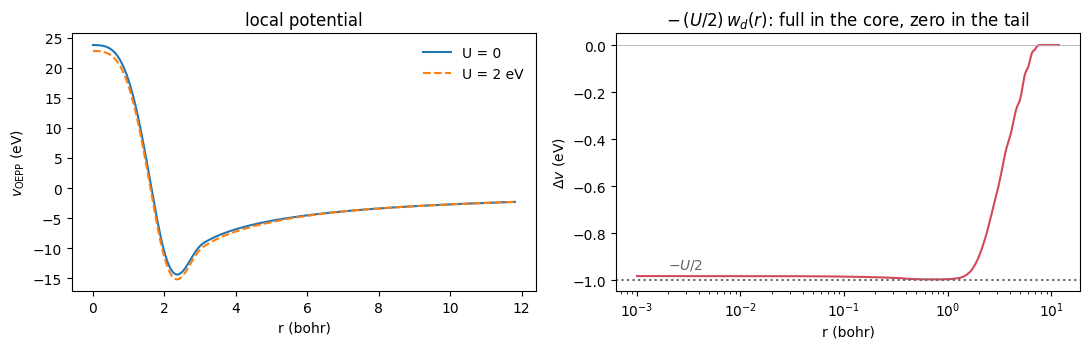

In [6]:
r = oepp_u.radial_grid
dV = (oepp_u.local_potential_ry - oepp_0.local_potential_ry) * HA / 2

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
m = (r > 1e-3) & (r < 12)
ax[0].plot(r[m], oepp_0.local_potential_ry[m] * HA / 2, label="U = 0")
ax[0].plot(r[m], oepp_u.local_potential_ry[m] * HA / 2, "--",
               label=f"U = {U_EV:g} eV")
ax[0].set_xlabel("r (bohr)"); ax[0].set_ylabel(r"$v_{\rm OEPP}$ (eV)")
ax[0].set_title("local potential"); ax[0].legend(frameon=False)

ax[1].semilogx(r[m], dV[m], color="#d1495b")
ax[1].axhline(-U_EV / 2, ls=":", color="0.4")
ax[1].text(2e-3, -U_EV / 2 + 0.05, r"$-U/2$", color="0.4")
ax[1].axhline(0, lw=0.6, color="0.7")
ax[1].set_xlabel("r (bohr)"); ax[1].set_ylabel(r"$\Delta v$ (eV)")
ax[1].set_title(r"$-\,(U/2)\,w_d(r)$: full in the core, zero in the tail")
fig.tight_layout()

print(f"min dV = {dV.min():.3f} eV   (-U/2 = {-U_EV/2:.3f})")
print(f"dV beyond r = 20 bohr: {np.abs(dV[r > 20]).max():.2e} eV")

### Optional: travel the d block inside the pseudopotential

`alpha_d(omega)` is a property of the ion, so the pole set can live in the
UPF's `PP_INFO` and `dftpy.td.d_embedding.poles_from_upf` will read it back.
The shift holds the **dipole** fixed: with $f = 2\omega D^2$,

$$\omega' = \omega + U_{\rm eff}/2,\qquad f' = f\,\omega'/\omega,\qquad D' = D.$$

Each set records `u_eff_ev_applied`, and `attach_d_block` refuses a run-time
`d_shift_ev` on top of it so U cannot be counted twice.

This is shown for completeness.  **It is not the lever this workflow uses** —
see the note in stage 4.

In [7]:
EPS = SCF / "HP" / "EPS"
POLES = {"bulk_werner": (EPS / "d_poles_werner.npz", "solid-state"),
         "bulk_johnson": (EPS / "d_poles_measured.npz", "solid-state")}
have = {k: v for k, v in POLES.items() if v[0].exists()}
if have:
    blk = oepp_u.d_block(have, u_applied=U_EV, default="bulk_werner")
    s = blk["pole_sets"]["bulk_werner"]
    print(f"pole set 'bulk_werner', U_eff = {U_EV:g} eV baked in")
    print("   omega (eV):", s["omega_ev"])
    if "alpha_static_bare" in s:
        print(f"   alpha: {s['alpha_static_bare']:.3f} -> "
              f"{s['alpha_static_total']:.3f} bohr^3  (less polarizable)")
    print(f"   u_eff_ev_applied = {s['u_eff_ev_applied']}")
else:
    print(f"no pole files under {EPS} -- skipping")

pole set 'bulk_werner', U_eff = 2 eV baked in
   omega (eV): [5.9575, 8.0205, 11.3834, 15.3965, 20.8349, 31.0782]
   alpha: 13.928 -> 12.708 bohr^3  (less polarizable)
   u_eff_ev_applied = 2.0


## 3. Ground-state density with the OEPP+U  *(reused)*

The orbital-free response is built on its **own** ground state, so pairing a
U = 0 density with an OEPP+U Hamiltonian would be inconsistent: the density
has to be redone for every U.

```bash
cd Ag/Ag6/GS_KS   && sbatch --export=ALL,U=2 run_density_u.sh   # -> OEPPU2/
cd Ag/Ag6/GS_LMGP && sbatch --export=ALL,U=2 run_density_u.sh   # the OF route
```

We take the KS route here (`route = ks`), so the response is built on the KS
density with the von Weizsacker inversion.  The LMGP route swaps the density
and the external potential and is otherwise identical.

In [8]:
dens_u = AG / "GS_KS" / f"OEPPU{U_EV:g}" / f"{CLUSTER.lower()}_u{U_EV:g}_ks_rho_scf.xsf"
dens_0 = next((AG / "GS_KS" / "OEPP").glob("*_rho_scf.xsf"))
for p in (dens_0, dens_u):
    assert p.exists(), f"missing {p}"
meta = AG / "GS_KS" / f"OEPPU{U_EV:g}" / f"{CLUSTER.lower()}_u{U_EV:g}_ks_metadata.json"
if meta.exists():
    m = json.load(open(meta))
    pp = next((str(v).split("/")[-1] for v in m.values()
               if isinstance(v, str) and ".UPF" in str(v)), "?")
    print(f"U = {U_EV:g} density was built with PP = {pp}")
print(f"U = 0 density : {dens_0.name}")
print(f"U = {U_EV:g} density : {dens_u.name}")

U = 2 density was built with PP = Ag_OEPP_U2_Mi2016.UPF
U = 0 density : ag6_ks_mpi_rho_scf.xsf
U = 2 density : ag6_u2_ks_rho_scf.xsf


## 4. Linear response with the d embedding  *(runs)*

`OFLanczos` solves the orbital-free Casida problem by recursion.  With a d
block attached the coupled operator is

$$\tilde D=\begin{pmatrix}D&0\\0&\omega_d\end{pmatrix},\qquad
  \tilde M=\begin{pmatrix}M&S\\S^{\!\top}&\omega_d+2K_{dd}\end{pmatrix}$$

and `d_shift_ev` raises every 4d → virtual transition by $U/2$ — the second
of the two U operators.

**Which d block is used matters.**  `attach_d_block` calls
`build_d_modes_local`, which builds **explicit atomic** 4d → np/nf
transitions from the radial orbitals carried in the pseudopotential's own
d block (126 modes for Ag6: 7 transitions × 6 atoms × 3).  The bulk pole set from stage 2 is only
consulted when `D_SOURCE=bulk`.  So in this configuration the single U lever
is `d_shift_ev`, and a UPF-baked pole set would be ignored.

In [9]:
def build_lr(dens_path, pseudo_path):
    '''Everything up to the recursion: v_s, the kernels, the ions, the grid.'''
    ions, rho, _ = io.read_all(str(dens_path), full=True)
    rho_inv, tinfo = replace_tail(rho, verbose=False)   # ks route needs this
    pseudo = Functional(type="PSEUDO", grid=rho.grid, ions=ions,
                        PP_list={"Ag": str(pseudo_path)})
    xc = Functional(type="XC", name="LDA", core_density=pseudo.core_density)
    hartree = Functional(type="HARTREE")
    ke = Functional(type="KEDF", name="TFvW"); ke.options.update({"y": 0})
    vw = Functional(type="KEDF", name="Vw")
    # ks route: v_s is MINUS the KS potential that the density came from
    v_ks = (pseudo(rho_inv).potential + hartree(rho_inv).potential
            + xc(rho_inv).potential + ke(rho_inv).potential
            + vw(rho_inv).potential)
    total = TotalFunctional(KEDF=ke, XC=xc, HARTREE=hartree, PSEUDO=pseudo)
    total.UpdateFunctional(newFuncDict={"EXT": ExternalPotential(v=-v_ks)})
    v_s = np.asarray(total(rho_inv, calcType={"V"}).potential, float)

    rho_i = np.asarray(rho_inv, float)                  # clamp the vacuum
    far = rho_i < 1e-9
    shell = (rho_i >= 1e-9) & (rho_i < 1e-8)
    if far.any() and shell.any():
        v_s = np.where(far, float(np.median(v_s[shell])), v_s)
    v_s = np.clip(v_s, -50.0 / HA, 50.0 / HA)

    f_loc = np.asarray(TotalFunctional(KEDF=ke, XC=xc)(
        rho, calcType=["V2"]).v2rho2, float)
    f_xc_d = np.asarray(xc(rho, calcType=["V2"]).v2rho2, float)
    return v_s, np.asarray(rho, float), rho_i, f_loc, f_xc_d, ions, rho.grid


def run_lr(dens_path, pseudo_path, u_ev, label):
    v_s, rho, rho_inv, f_loc, f_xc_d, ions, grid = build_lr(dens_path, pseudo_path)
    n_e = float(rho.sum()) * grid.dV
    lz = OFLanczos(v_s, rho, f_loc, grid.lattice, ecut=ECUT, workers=-1)
    guess = np.sqrt(np.maximum(rho_inv, 0.0))
    lz.set_ground_state(guess, 0.0)                     # psi0 = sqrt(rho)
    lz.mu = lz.dot(lz.phi0, lz._h0(lz.phi0))
    info = lz.attach_d_block(np.asarray(ions.positions, float), f_xc_d,
                             cut_bohr=10.0, d_shift_ev=0.5 * u_ev,
                             upf=str(pseudo_path))
    print(f"{label}: N = {n_e:.4f}, {lz.npw} PWs, d block {lz.n_d} modes "
          f"({info['n_trans']} transitions), d_shift = {0.5*u_ev:g} eV")
    print(f"   omega_d = {np.round(info['omega_ev'], 2)} eV, "
          f"alpha = {info['alpha']:.2f} bohr^3")
    rr = np.asarray(grid.r, float)
    W, F = [], []
    for d in DIRS:
        t0 = time.time()
        a, b, n2, cs = lz.lanczos_sd(lz.dipole_vector(rr[d]),
                                     np.zeros(lz.n_d), NSTEPS)
        w, f = lz.sticks(a, b, n2)
        W.append(w); F.append(f)
        print(f"   dir {d}: {len(a)} steps, {time.time()-t0:.0f} s, "
              f"f-sum = {2*n2:.3f} of {n_e:.1f}")
    return np.concatenate(W), np.concatenate(F) / len(DIRS), n_e

In [ ]:
t0 = time.time()
w0, f0, ne = run_lr(dens_0, SCF / "OEPP" / "Ag_OEPP_PZ.UPF", 0.0, "U = 0")
print()
wu, fu, _ = run_lr(dens_u, upf_u, U_EV, f"U = {U_EV:g} eV")
print(f"\ntotal {time.time()-t0:.0f} s")

setting key: Ag -> /projectsn/mp1009_1/Valeria/Plasmons/Ag_SCF+U/OEPP/Ag_OEPP_PZ.UPF
U = 0: N = 6.0000, 81502 PWs, d block 126 modes (7 transitions), d_shift = 0 eV
   omega_d = [ 6.82  7.97  8.61  9.62  8.38  9.2  10.27] eV, alpha = 10.70 bohr^3


## 5. The optical spectrum

The recursion returns oscillator sticks $(\omega_j, f_j)$.  Broadening them
with a Lorentzian of width `GAMMA_EV` gives the strength function; the f-sum
over all sticks must come back to the electron count, which is the check that
the response is complete.

peak  U = 0     : 3.2487 eV
peak  U = 2 eV  : 3.4587 eV      shift +0.2100 eV
f-sum U = 0     : 6.001 of N = 6.0
f-sum U = 2 eV  : 6.001 of N = 6.0


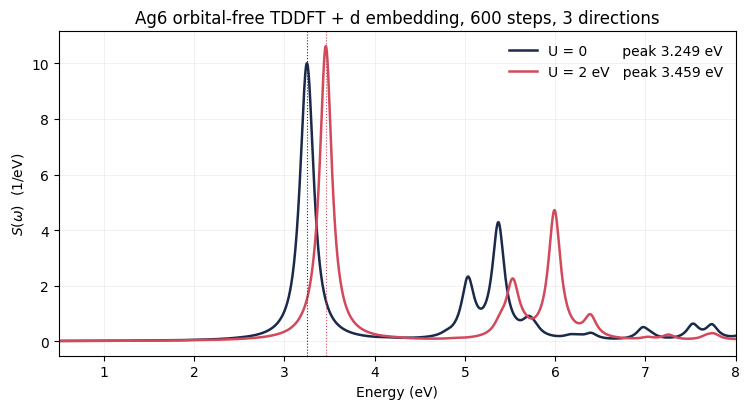

In [13]:
def spectrum(w, f, lo=0.5, hi=8.0, n=2001, gamma=GAMMA_EV):
    e = np.linspace(lo, hi, n)
    o = np.asarray(w) * HA
    s = np.zeros_like(e)
    for oi, fi in zip(o, f):
        s += fi * (gamma / np.pi) / ((e - oi) ** 2 + gamma ** 2)
    return e, s

e, s0 = spectrum(w0, f0)
_, su = spectrum(wu, fu)
pk0, pku = e[np.argmax(s0)], e[np.argmax(su)]

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.plot(e, s0, lw=1.8, color="#1b2a4a", label=f"U = 0        peak {pk0:.3f} eV")
ax.plot(e, su, lw=1.8, color="#d1495b", label=f"U = {U_EV:g} eV   peak {pku:.3f} eV")
ax.axvline(pk0, ls=":", lw=0.8, color="#1b2a4a")
ax.axvline(pku, ls=":", lw=0.8, color="#d1495b")
ax.set_xlabel("Energy (eV)"); ax.set_ylabel(r"$S(\omega)$  (1/eV)")
ax.set_title(f"{CLUSTER} orbital-free TDDFT + d embedding, "
             f"{NSTEPS} steps, {len(DIRS)} directions")
ax.legend(frameon=False); ax.set_xlim(e[0], e[-1]); ax.grid(alpha=.25, lw=.5)
fig.tight_layout()

print(f"peak  U = 0     : {pk0:.4f} eV")
print(f"peak  U = {U_EV:g} eV  : {pku:.4f} eV      shift {pku-pk0:+.4f} eV")
print(f"f-sum U = 0     : {f0.sum():.3f} of N = {ne:.1f}")
print(f"f-sum U = {U_EV:g} eV  : {fu.sum():.3f} of N = {ne:.1f}")

## 6. Check against the stored production runs

The project's own results carry their configuration in `metadata`, so the
notebook can be checked against them rather than trusted.  Expect agreement
to a few tens of meV: we ran fewer Lanczos steps here.

The three rows separate the two U operators:

| run | U in the pseudopotential | U in the d transitions |
|---|---|---|
| `d_val` | no | no |
| `d_val_u2` | no | yes |
| `d_val_u2_ppu2_at` | yes | yes |

In [14]:
LR = AG / "LR_OF" / "FROM_KS"
want = [f"lanczos_ks_{CLUSTER}_d_val.npz",
        f"lanczos_ks_{CLUSTER}_d_val_u{U_EV:g}.npz",
        f"lanczos_ks_{CLUSTER}_d_val_u{U_EV:g}_ppu{U_EV:g}_at.npz"]
print(f"  {'file':52s} {'peak (eV)':>10} {'U_pp':>6} {'d_shift':>8}")
for n in want:
    p = LR / n
    if not p.exists():
        print(f"  {n:52s}  (absent)"); continue
    m = json.loads(str(np.load(p, allow_pickle=True)["metadata"]))
    in_pp = "yes" if "OEPPU" in m.get("density_file", "") or \
                     "OEPP_U" in m.get("density_file", "") else "no"
    print(f"  {n:52s} {m.get('peak_ev', float('nan')):>10.4f} "
          f"{in_pp:>6} {m.get('d_shift_ev', 0):>8.2f}")
print(f"\n  this notebook, U = 0    : {pk0:.4f} eV")
print(f"  this notebook, U = {U_EV:g} eV : {pku:.4f} eV   "
      f"(pseudopotential + d shift, so compare with the _ppu row)")

  file                                                  peak (eV)   U_pp  d_shift
  lanczos_ks_Ag6_d_val.npz                                 3.2510     no     0.00


  lanczos_ks_Ag6_d_val_u2.npz                              3.2915     no     1.00
  lanczos_ks_Ag6_d_val_u2_ppu2_at.npz                      3.4580    yes     1.00

  this notebook, U = 0    : 3.2487 eV
  this notebook, U = 2 eV : 3.4587 eV   (pseudopotential + d shift, so compare with the _ppu row)


## Summary

```
run_qepy_wavefunctions.py   QEpy SCF with hubbard {atomic} U Ag-4d <U>
        |                   -> qepy_U<U>/qepy_wfs.npz
        v
OEPP.from_ks(...)           Mi Eq. (15) Slater average, d channel + Dudarev
        |                   -> Ag_OEPP_U<U>_Mi2016.UPF
        v
GS_KS/run_density_u.sh      ground-state density under that pseudopotential
        |                   -> GS_KS/OEPPU<U>/..._rho_scf.xsf
        v
OFLanczos.attach_d_block    explicit atomic 4d modes, shifted by U/2
  + lanczos_sd              -> sticks -> broadened spectrum
```

Things that are easy to get wrong, and where this notebook guards against
them:

* **The density must match the pseudopotential.** A U = 0 density under an
  OEPP+U Hamiltonian is inconsistent; stage 3 redoes it per U.
* **U is not a constant shift of `v_OEPP`.** It enters inside the Slater
  average and comes out as $-(U/2)w_d(r)$, which vanishes in the tail.
* **Only one d-block U lever is active.** `d_shift_ev` shifts explicit atomic
  transitions; a UPF-baked pole set needs `D_SOURCE=bulk` and is a different
  physical model, not a different switch.
* **The f-sum is the check.** If it does not return the electron count the
  response is incomplete and the peak is not trustworthy.